# Week Problem Set: Data Wrangling

## Context
You are a Data Scientist at a regional health center. Patient data is divided across three systems:
- Administrative
- Lab Results
- Lifestyle Surveys

For this assignment, you will work with these datasets **independently** and focus only on **data wrangling tasks**.

---

## Datasets
1. patient_demographics.csv  
   - Patient ID, Age, Sex, Geography
     

2. clinical_data.csv  
   - Patient ID, Cholesterol, Blood Pressure ("120/80"), BMI
  

3. lifestyle_factors.csv  
   - Patient ID, Smoking, Diet, Heart Attack Risk (Target)

---

## Objectives
- Inspecting structure and quality
- Handling missing values
- Fixing data formats
- Identifying and treating anomalies

---

## Important Note
This is a guided notebook. You are expected to:
- Think critically
- Make decisions (and justify them)
- Explore different approaches

---

In [52]:
#importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
#dataset ko file lai set gareko

import os 

BASE_DIR = os.path.dirname(os.getcwd())

patient_demographics_file = os.path.join(BASE_DIR,"dataset","patient_demographics.csv")
clinical_file = os.path.join(BASE_DIR,"dataset","clinical_data.csv")
lifestyle_file = os.path.join(BASE_DIR,"dataset","lifestyle_factors.csv")

In [54]:
#loading datasets
demographics = pd.read_csv(patient_demographics_file)
clinical = pd.read_csv(clinical_file)
lifestyle = pd.read_csv(lifestyle_file)

# Basic Inspection

## Tasks:
- View first few rows
- Check datatypes
- Look at summary statistics

## Questions:
- Are there obvious data issues?
- Are datatypes appropriate?

## Hint:
- Use `.head()`, `.info()`, `.describe()` for all three dataframes to get a full picture of the data quality.
- Pandas documentation for reference: https://pandas.pydata.org/docs/user_guide/10min.html

In [55]:
demographics.head()


,Patient ID,Age,Sex,Income,Country,Continent,Hemisphere
0,BMW7812,67,Male,261404,Argentina,South America,Southern Hemisphere
1,CZE1114,21,Male,285768,Canada,North America,Northern Hemisphere
2,BNI9906,21,Female,235282,France,Europe,Northern Hemisphere
3,JLN3497,84,Male,125640,Canada,North America,Northern Hemisphere
4,GFO8847,66,Male,160555,Thailand,Asia,Northern Hemisphere


In [56]:
#datatype check garna lai .info()

clinical.info()

<class 'pandas.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Patient ID      8763 non-null   str    
 1   Cholesterol     8763 non-null   int64  
 2   Blood Pressure  8763 non-null   str    
 3   Heart Rate      8763 non-null   int64  
 4   Diabetes        8763 non-null   int64  
 5   Family History  8763 non-null   int64  
 6   Triglycerides   8763 non-null   int64  
 7   BMI             8763 non-null   float64
dtypes: float64(1), int64(5), str(2)
memory usage: 547.8 KB


In [57]:
#summary herna lai .describe()

clinical.describe(include='all')

,Patient ID,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Triglycerides,BMI
count,8763,8763.000000,8763,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000
unique,8763,NaN,3915,NaN,NaN,NaN,NaN,NaN
top,BMW7812,NaN,146/94,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,8,NaN,NaN,NaN,NaN,NaN
mean,NaN,259.877211,NaN,75.021682,0.652288,0.492982,417.677051,28.891446
std,NaN,80.863276,NaN,20.550948,0.476271,0.499979,223.748137,6.319181
min,NaN,120.000000,NaN,40.000000,0.000000,0.000000,30.000000,18.002337
25%,NaN,192.000000,NaN,57.000000,0.000000,0.000000,225.500000,23.422985
50%,NaN,259.000000,NaN,75.000000,1.000000,0.000000,417.000000,28.768999
75%,NaN,330.000000,NaN,93.000000,1.000000,1.000000,612.000000,34.324594


In [58]:
#Check missing values in each dataset
print("Missing values :) Demographics:")
print(demographics.isnull().sum())

print("\nMissing values :) Clinical:")
print(clinical.isnull().sum())

print("\nMissing values :) Lifestyle:")
print(lifestyle.isnull().sum())

Missing values :) Demographics:
Patient ID    0
Age           0
Sex           0
Income        0
Country       0
Continent     0
Hemisphere    0
dtype: int64

Missing values :) Clinical:
Patient ID        0
Cholesterol       0
Blood Pressure    0
Heart Rate        0
Diabetes          0
Family History    0
Triglycerides     0
BMI               0
dtype: int64

Missing values :) Lifestyle:
Patient ID                 0
Smoking                    0
Obesity                    0
Alcohol Consumption        0
Exercise Hours Per Week    0
Diet                       0
Stress Level               0
Heart Attack Risk          0
dtype: int64


# Data Cleaning

## 1. Blood Pressure Column

### Task:
- Inspect the Blood Pressure column

### Questions:
- Is it stored as a number or string?
- Can we compute averages directly?

### Hint:
- Format looks like "120/80"
- Consider splitting into two columns
- https://pandas.pydata.org/docs/reference/api/pandas.Series.str.split.html

### Consequences:
- Keeping as string -> limits analysis
- Splitting -> enables calculations but increases feature count

In [59]:
clinical['Blood Pressure'].head(10)

0     158/88
1     165/93
2     174/99
3    163/100
4      91/88
5     172/86
6     102/73
7     131/68
8    144/105
9     160/70
Name: Blood Pressure, dtype: str

In [60]:
clinical['Blood Pressure'].dtype

<StringDtype(storage='python', na_value=nan)>

In [61]:
# clinical['Blood Pressure'].mean() -> since Blood Pressure Column ma String Values haru chan so mean nikalna mildaina Error aaucha

In [62]:
#blood pressure ko values lai seperate column ma rakheko
clinical[
  ["Systolic","Diastolic"]
  ] = clinical["Blood Pressure"].str.split("/",expand=True).astype(int)

clinical.head()

,Patient ID,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Triglycerides,BMI,Systolic,Diastolic
0,BMW7812,208,158/88,72,0,0,286,31.251233,158,88
1,CZE1114,389,165/93,98,1,1,235,27.194973,165,93
2,BNI9906,324,174/99,72,1,0,587,28.176571,174,99
3,JLN3497,383,163/100,73,1,1,378,36.464704,163,100
4,GFO8847,318,91/88,93,1,1,231,21.809144,91,88


In [81]:
clinical['Systolic'].mean()

np.float64(135.07565902088325)

## 2. Missing Values

### Task:
Identify columns with null values

### Questions:
- Which columns have missing values?
- Why might values be missing?

### Hint:
- Lifestyle → user did not answer (non-critical)
- Clinical → test not performed (critical)
- https://wesmckinney.com/book/data-cleaning

### Why Missing Data Matters
Missing data is not just an inconvenience, it can affect the **validity of your analysis**.

There are different types of missingness:
- **MCAR (Missing Completely at Random)** → no pattern (least problematic)
- **MAR (Missing at Random)** → depends on other variables
- **MNAR (Missing Not at Random)** → depends on the missing value itself (most problematic)

Understanding *why* data is missing helps decide how to handle it.

### Consequences of Different Choices

#### 1. Dropping Missing Values (`dropna`)
- Pros: simple, clean dataset  
- Cons: loses data, may introduce bias  

---

#### 2. Filling Missing Values (`fillna`)
- Pros: keeps dataset size, usable for modeling  
- Cons: adds assumptions, can distort data  

---

#### 3. Column-Specific Strategy
- Clinical → careful imputation or flag missing  
- Lifestyle → consider "Unknown" category  

### Key Takeaway:
There is **no single correct method**.  
The best approach depends on:
- Why data is missing  
- How much is missing  
- The impact on downstream analysis  


In [64]:
clinical.isna().sum()

Patient ID        0
Cholesterol       0
Blood Pressure    0
Heart Rate        0
Diabetes          0
Family History    0
Triglycerides     0
BMI               0
Systolic          0
Diastolic         0
dtype: int64

In [65]:
lifestyle.isna().sum()

Patient ID                 0
Smoking                    0
Obesity                    0
Alcohol Consumption        0
Exercise Hours Per Week    0
Diet                       0
Stress Level               0
Heart Attack Risk          0
dtype: int64

In [66]:
demographics.isna().sum()

Patient ID    0
Age           0
Sex           0
Income        0
Country       0
Continent     0
Hemisphere    0
dtype: int64

# Exploratory Data Analysis (EDA)

## Univariate Analysis: Age Distribution

Univariate analysis examines **one variable at a time**.
The goal is to understand each column's distribution, central tendency, and spread before comparing variables.

We split variables into two types:
- **Numerical** (continuous): Age, Cholesterol, BMI, Blood Pressure
- **Categorical** (discrete): Sex, Smoking, Diet, Country

---

## 1. Numerical Variables : Distributions

### Task:
Plot histograms and KDE (Kernel Density Estimate) curves for: Age, Cholesterol, BMI

### Questions:
- Which variables are normally distributed?
- Which variables are skewed left or right?
- Are there any unexpected spikes or gaps?
- Based on the distribution shape, would any feature likely need a transformation before modeling?

### Hint:
- `sns.histplot(data=df, x='Age', kde=True)` draws a histogram with a density curve
- `plt.axvline(df['Age'].mean(), color='red', linestyle='--', label='Mean')` adds a mean line
- Skewness > 1 or < -1 is considered highly skewed

## Why This Matters

Many statistical models, such as **Linear Regression, Logistic Regression, and Linear Discriminant Analysis** assume that numerical features are approximately **normally distributed**. When this assumption is violated, it can lead to:

- Biased coefficients  
- Unreliable p-values  
- Poor model performance  

Even though tree-based models (like Decision Trees) do not require normality, highly skewed features can still negatively affect **distance-based algorithms** such as **KNN** or **SVM**.

This is why understanding the shape of your distributions early in **Exploratory Data Analysis (EDA)** is important. It helps determine whether transformations are needed before modeling.

---

## Common Transformations and When to Use Them

### 1. Log Transform — `np.log1p(x)`
Used when data is **right-skewed** (long tail on the right), such as income or cholesterol levels in some populations.

- Compresses large values  
- Pulls distribution closer to normal  
- Uses `log1p` (log(1 + x)) to safely handle zero values  

---

### 2. Square Root Transform — `np.sqrt(x)`
A milder transformation compared to log.

- Useful for **moderately right-skewed data**  
- Common for count data (e.g., number of medications)  
- Preserves more of the original structure  

---

### 3. Box-Cox Transform — `scipy.stats.boxcox(x)`
A powerful, data-driven transformation.

- Finds optimal power (λ) to best approximate normality  
- Requires all values to be **strictly positive**  
- Special cases:
  - λ = 0 → log transform  
  - λ = 0.5 → square root transform  

---

### 4. Yeo-Johnson Transform — `sklearn.preprocessing.PowerTransformer(method='yeo-johnson')`
A flexible alternative to Box-Cox.

- Works with **zero and negative values**  
- More suitable for real-world medical datasets  
- Automatically learns best transformation  

---

### 5. Standardization (Z-score) — `sklearn.preprocessing.StandardScaler`
Transforms features to have:

- Mean = 0  
- Standard deviation = 1  

Notes:

- Does **not change distribution shape**  
- Useful when features are on different scales (e.g., Age vs Cholesterol)  
- Does not fix skewness  

---

### 6. Min-Max Normalization — `sklearn.preprocessing.MinMaxScaler`
Rescales features to a fixed range:

- Values are scaled to **[0, 1]**  
- Does not fix skewness  

---

### Reference links:
- https://towardsdatascience.com/top-3-methods-for-handling-skewed-data-1334e0debf45/
- https://www.geeksforgeeks.org/python/data-normalization-with-pandas/


In [67]:
#patient_id ko basis ma merge garne sabai tables lai 

df = demographics.merge(clinical, on='Patient ID')
df = df.merge(lifestyle, on='Patient ID')

print(df.shape)
df.head()

(8763, 23)


,Patient ID,Age,Sex,Income,Country,Continent,Hemisphere,Cholesterol,Blood Pressure,Heart Rate,...,BMI,Systolic,Diastolic,Smoking,Obesity,Alcohol Consumption,Exercise Hours Per Week,Diet,Stress Level,Heart Attack Risk
0,BMW7812,67,Male,261404,Argentina,South America,Southern Hemisphere,208,158/88,72,...,31.251233,158,88,1,0,0,4.168189,Average,9,0
1,CZE1114,21,Male,285768,Canada,North America,Northern Hemisphere,389,165/93,98,...,27.194973,165,93,1,1,1,1.813242,Unhealthy,1,0
2,BNI9906,21,Female,235282,France,Europe,Northern Hemisphere,324,174/99,72,...,28.176571,174,99,0,0,0,2.078353,Healthy,9,0
3,JLN3497,84,Male,125640,Canada,North America,Northern Hemisphere,383,163/100,73,...,36.464704,163,100,1,0,1,9.828130,Average,9,0
4,GFO8847,66,Male,160555,Thailand,Asia,Northern Hemisphere,318,91/88,93,...,21.809144,91,88,1,1,0,5.804299,Unhealthy,6,0


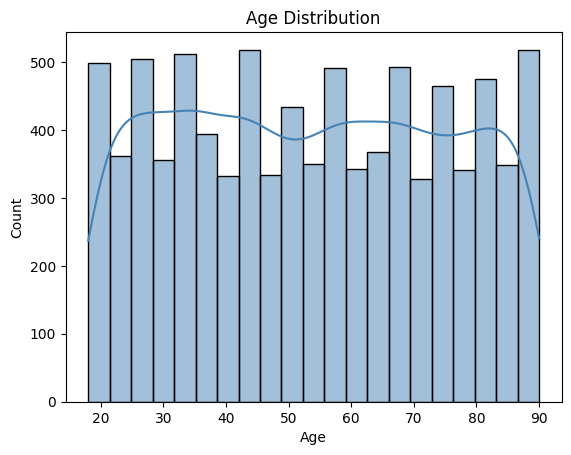

In [68]:
sns.histplot(data=df, x='Age', kde=True, color='steelblue')
plt.title('Age Distribution')
plt.show()

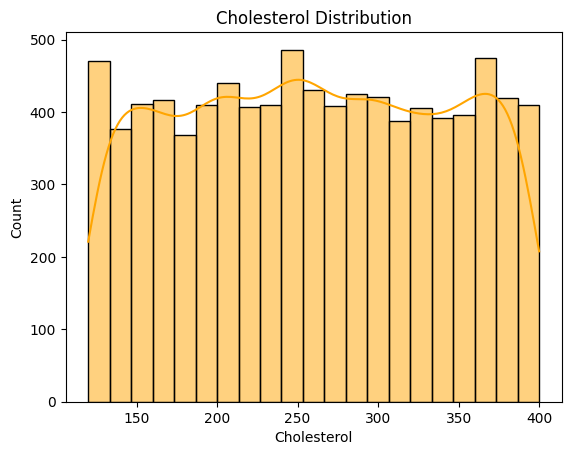

In [69]:
sns.histplot(data=df, x='Cholesterol', kde=True, color='orange')
plt.title('Cholesterol Distribution')
plt.show()

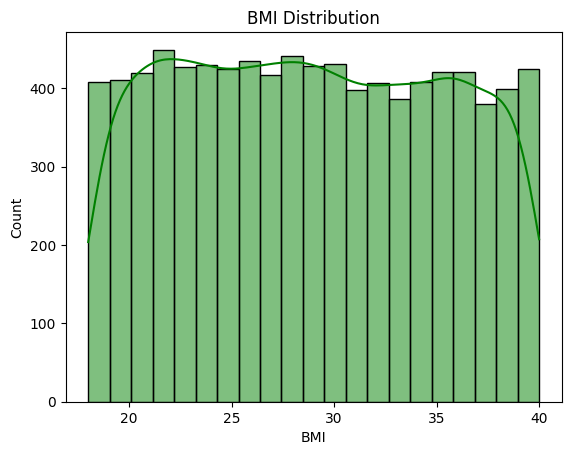

In [70]:
sns.histplot(data=df, x='BMI', kde=True, color='green')
plt.title('BMI Distribution')
plt.show()

## 2. Categorical Variables : Bar Charts

### Task:
Plot bar charts showing the frequency distribution of: Smoking Status, Diet Quality, and Top 10 Countries

### Questions:
- What proportion of patients smoke?
- Which diet category is most common?
- Which countries are most represented?

### Hint:
- `sns.countplot(data=df, x='Smoking', order=df['Smoking'].value_counts().index)` orders bars by frequency
- For Country, filter to top 10: `df['Country'].value_counts().head(10)`
- Rotate x-axis labels if needed: `plt.xticks(rotation=45)`

### Why This Matters:
Imbalanced categories (e.g., 90% male patients) can introduce bias into analyses. Knowing category proportions helps interpret group-level results accurately.

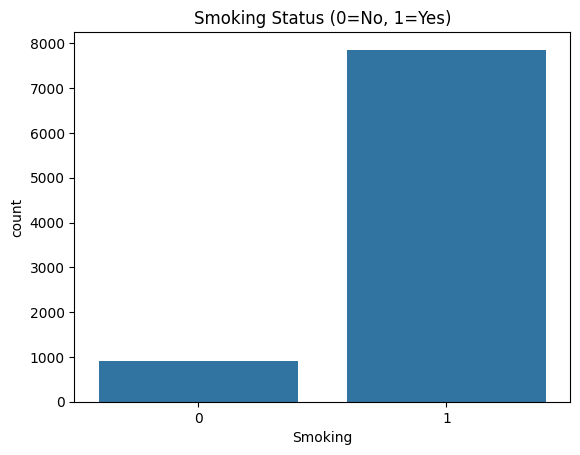

In [71]:
sns.countplot(data=df, x='Smoking')
plt.title('Smoking Status (0=No, 1=Yes)')
plt.show()

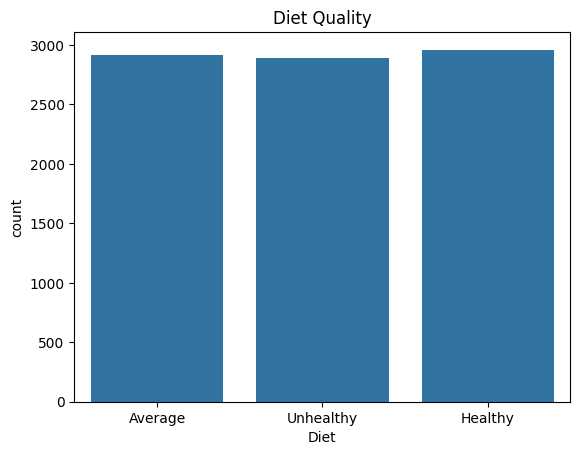

In [72]:
sns.countplot(data=df, x='Diet')
plt.title('Diet Quality')
plt.show()

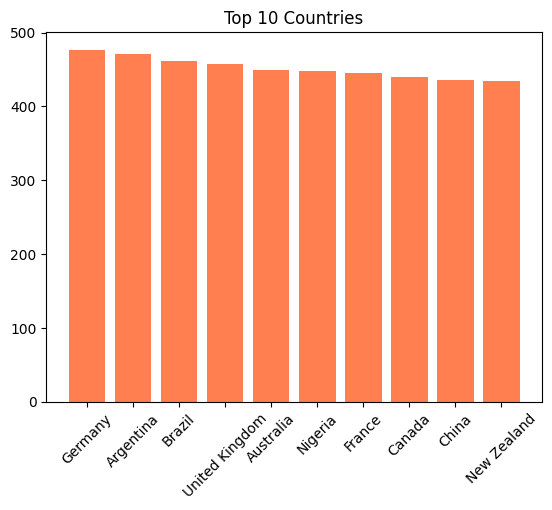

In [73]:
top10 = df['Country'].value_counts().head(10)

plt.bar(top10.index, top10.values, color='coral')
plt.title('Top 10 Countries')
plt.xticks(rotation=45)
plt.show()

# Bivariate Analysis : Features vs Target

## Context
Bivariate analysis explores the relationship **between two variables**.
Here, we are specifically interested in how each feature relates to `Heart Attack Risk` (our target).

This is where we start forming hypotheses:
- Do smokers have higher risk?
- Does diet quality affect risk?
- Does cholesterol level differ between risk groups?

---

## Categorical Features vs Heart Attack Risk (Grouped Bar Charts)

### Task:
For the categorical features: Smoking, Diet, Sex, create a grouped bar chart showing the count of At-Risk vs Not-At-Risk patients within each category.

### Questions:
- Do smokers show noticeably higher risk counts?
- Does diet quality appear protective against heart attack risk?
- Is there a difference in risk between male and female patients?

### Hint:
- `sns.countplot(data=df, x='Smoking', hue='Heart Attack Risk')` creates grouped bars automatically
- `hue` splits each bar group by the target variable
- To see proportions (not raw counts) within groups, compute:
  `df.groupby('Smoking')['Heart Attack Risk'].mean()` → gives risk rate per group

### Why This Matters:
Raw counts can be misleading if groups have unequal sizes. Consider also plotting proportions (risk rate) to compare groups fairly.

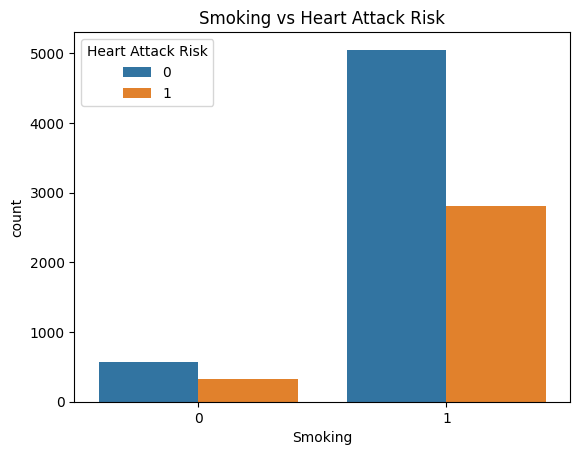

In [74]:
sns.countplot(data=df, x='Smoking', hue='Heart Attack Risk')
plt.title('Smoking vs Heart Attack Risk')
plt.show()

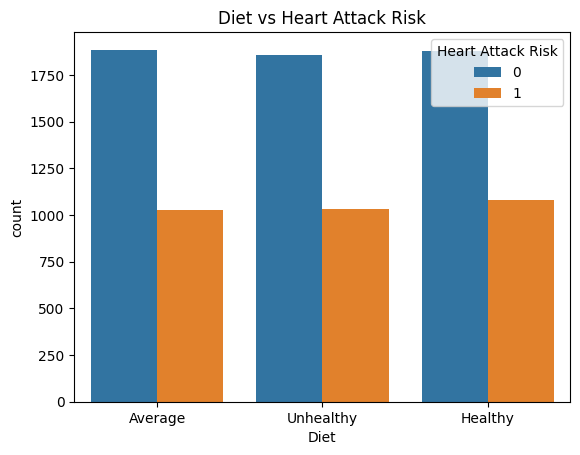

In [75]:
sns.countplot(data=df, x='Diet', hue='Heart Attack Risk')
plt.title('Diet vs Heart Attack Risk')
plt.show()

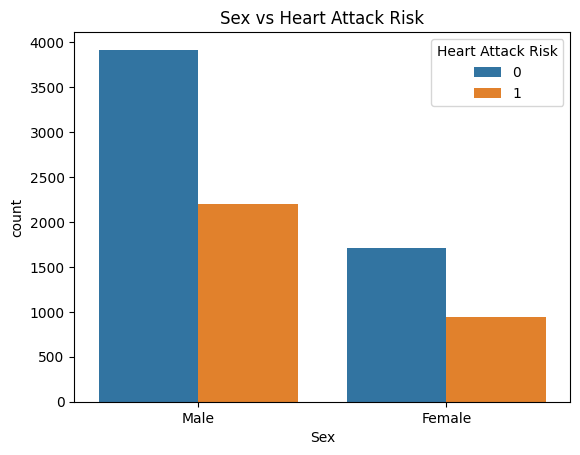

In [76]:
sns.countplot(data=df, x='Sex', hue='Heart Attack Risk')
plt.title('Sex vs Heart Attack Risk')
plt.show()

# Correlation Analysis

## Context
Correlation measures **how strongly two numerical variables move together**.

### Some types of Correlation Coefficient:
| Coefficient | Use Case | Range |
|---|---|---|
| **Pearson** | Linear relationship between continuous variables | -1 to +1 |
| **Spearman** | Monotonic (ranked) relationship; robust to outliers | -1 to +1 |

### Interpretation Guide:
- |r| > 0.7 → Strong correlation  
- |r| 0.4–0.7 → Moderate correlation  
- |r| < 0.4 → Weak correlation  
- Sign (+ or -) tells direction: positive = both increase together, negative = one increases as other decreases

---

## Pearson Correlation Heatmap

### Task:
Calculate and visualize the Pearson correlation matrix for all numerical columns including the target.

### Questions:
- Which feature has the highest correlation with Heart Attack Risk?
- Are any features highly correlated with each other (multicollinearity)?
- Does Systolic BP correlate strongly with Diastolic BP? Why might that be expected?

### Hint:
- `df[numeric_cols].corr(method='pearson')` computes the correlation matrix
- `sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')` visualizes it
- `mask = np.triu(np.ones_like(corr_matrix))` removes the duplicate upper triangle

### Warning:
Pearson assumes linearity and is sensitive to outliers. For skewed distributions, consider Spearman instead.

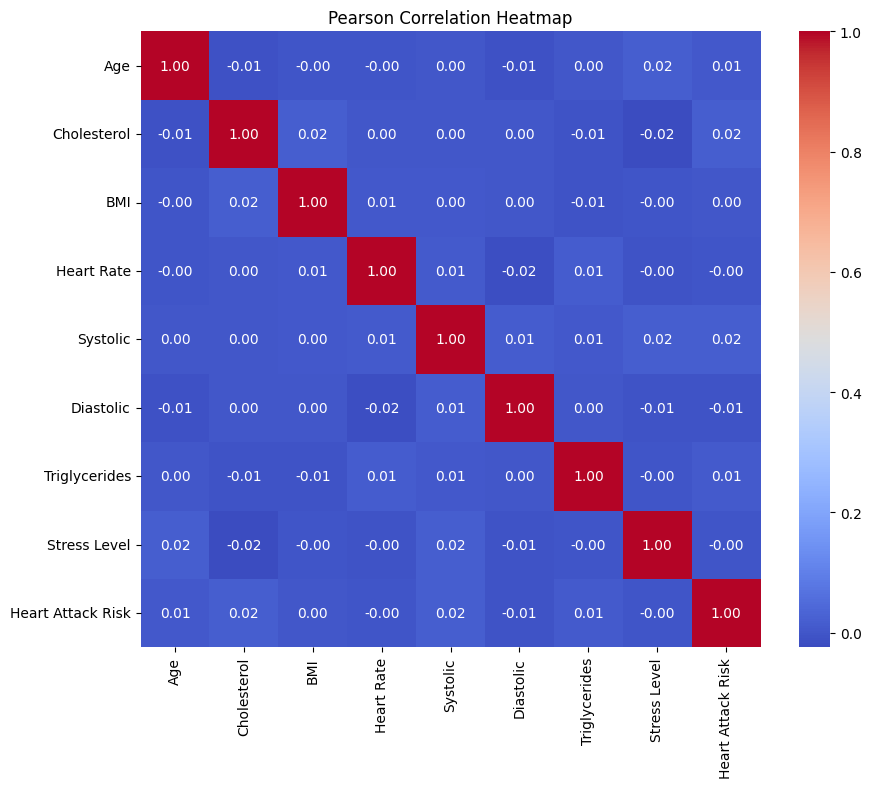

In [77]:
# Pick only number columns
num_cols = ['Age', 'Cholesterol', 'BMI', 'Heart Rate',
            'Systolic', 'Diastolic', 'Triglycerides',
            'Stress Level', 'Heart Attack Risk']

corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Pearson Correlation Heatmap')
plt.show()

# Spearman Correlation

### Task:
Repeat the correlation analysis using Spearman's rank correlation.

### Questions:
- Are the Spearman results significantly different from Pearson?
- If they differ, what might that suggest about the data's linearity or outliers?

### Hint:
- Use `method='spearman'` in `.corr()`
- Compare the two heatmaps side by side using `plt.subplots(1, 2)`

### Interpretation:
Large differences between Pearson and Spearman suggest the relationship is non-linear or that outliers are influencing Pearson.

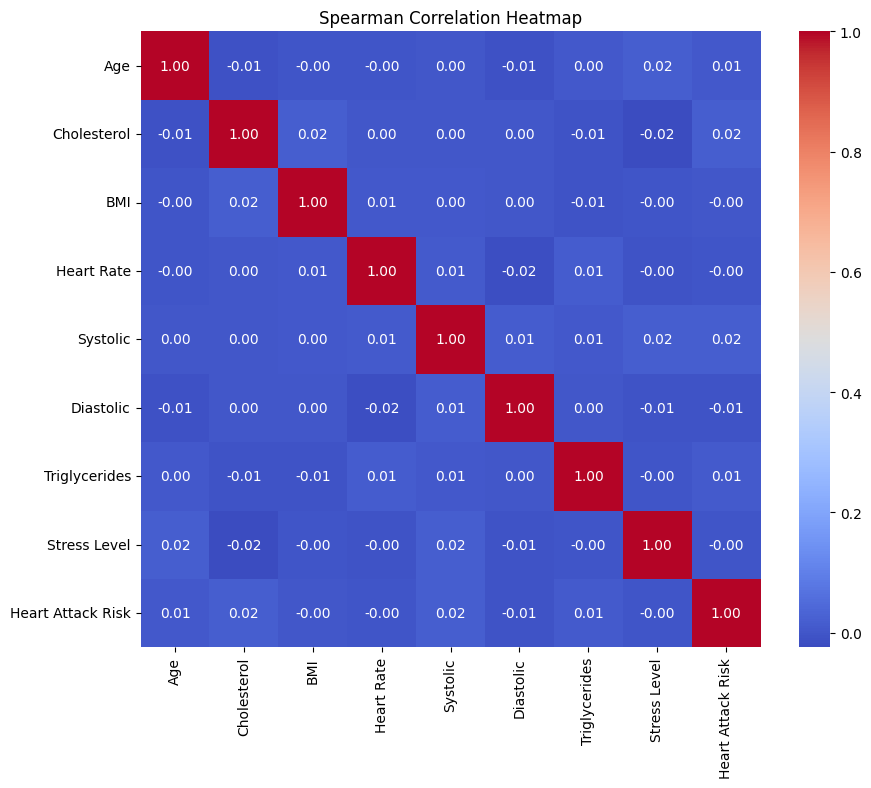

In [78]:
corr_sp = df[num_cols].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_sp, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Spearman Correlation Heatmap')
plt.show()

## Target Variable Analysis: Heart Attack Risk

## Context
Target variable is the variable that the user would want to predict using the rest of the dataset.

`Heart Attack Risk` is a **binary variable**: 0 (No Risk) and 1 (At Risk).

## Tasks:
- Count how many patients fall into each class
- Visualize the class distribution with a bar chart

## Hint:
- Use `.value_counts()` to get counts
- Use `sns.countplot()` or `plt.bar()` for visualization


In [79]:
# Count values
print(df['Heart Attack Risk'].value_counts())

Heart Attack Risk
0    5624
1    3139
Name: count, dtype: int64


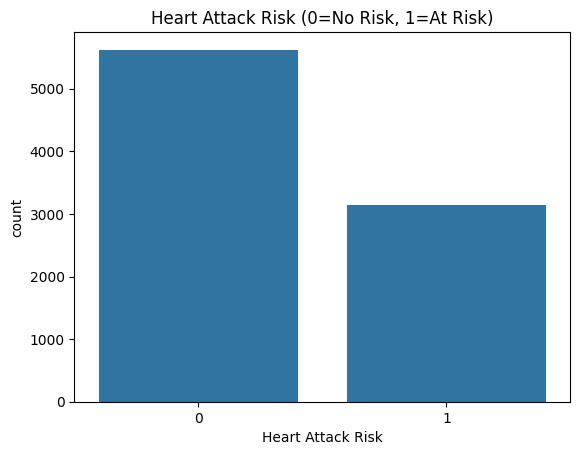

In [80]:
# Bar chart of target
sns.countplot(data=df, x='Heart Attack Risk')
plt.title('Heart Attack Risk (0=No Risk, 1=At Risk)')
plt.show()

# Final Reflection

## Answer the following:

### 1. Missing Values
- How did you handle missing values in each dataset?
- Why did you choose that approach (drop, fill, or mixed strategy)?

---

### 2. Data Quality Issues
- Did you find any unrealistic or inconsistent values?
- How did you identify them?
- What action did you take (remove, clip, correct, or keep)?

---

### 3. Insights from EDA
- What patterns did you observe in the data?
- Did you find any relationships between variables (e.g., age, cholesterol, risk)?
- Were there any surprising findings or trends?

---

### 4. Correlation Findings
- Were Pearson and Spearman results similar or different? What does that suggest?
- Did you find any multicollinearity (two features highly correlated with each other)?

---

### 5. Improvements
- If you had more time, what would you improve in your data cleaning process?
- Would you try different strategies for missing values or outliers?
- What additional checks or visualizations would you add?

---

### Tip
There is no single correct answer here. Focus on:
- Justifying your decisions  
- Explaining trade-offs  
- Demonstrating understanding of data quality impact  

### Answer here:

## 1. Missing Values

**How did you handle missing values?**  
I used `isnull().sum()` to check for missing values. There were no missing values in any of the datasets.

**Why did you choose this approach?**  
Since there were no missing values, I did not need to do any cleaning.

If missing values were present:
- Clinical data (Cholesterol, BMI) → fill with median  
- Lifestyle data (Smoking, Diet) → fill with "Unknown"  
- Demographic data (Age, Country) → drop rows if only a few values are missing  

Filling keeps all data but may add assumptions. Dropping removes data but makes it cleaner.

---

## 2. Data Quality Issues

**Did you find any unrealistic or inconsistent values?**  
Yes. The Blood Pressure column was stored as a string like "120/80" instead of numeric values.

**How did you identify it?**  
I checked the data type and it was an object (string).  
I also tried to calculate the mean, but it gave an error.

**What action did you take?**  
I split the Blood Pressure column into two new columns:
- Systolic (top value)
- Diastolic (bottom value)

Then I converted both columns to integers using `.astype(int)`.

---

## 3. Insights from EDA

**What patterns did you observe?**  
- Age is normally distributed  
- Cholesterol is symmetric  
- BMI is normally distributed  
- Smoking is highly imbalanced (about 90% smokers)  
- Diet is fairly balanced  
- Heart Attack Risk has more "No Risk" cases than "At Risk"  

**Did you find any relationships between variables?**  
- Cholesterol and Systolic BP have a weak relationship with risk  
- Systolic and Diastolic are strongly related since they come from the same measurement  

**Were there any surprising findings?**  
- All numerical variables were already normally distributed, which is unusual  
- Correlation values were very low, so single variables are not strong predictors  

---

## 4. Correlation Findings

**Were Pearson and Spearman results similar or different? What does that suggest?**  
They were almost the same.  
For example:
- Cholesterol → 0.019  
- Age → 0.006  

This suggests that the relationships are linear and there are no strong outliers.

**Did you find any multicollinearity?**  
Yes, Systolic and Diastolic are correlated because they come from the same Blood Pressure value.  
No other strong correlations were found.

---

## 5. Improvements

**What would you improve in the data cleaning process?**  
- Use box plots to detect outliers  
- Create a new feature called Mean Arterial Pressure (MAP):  
  MAP = Diastolic + (1/3)(Systolic − Diastolic)  

**Would you try different strategies for missing values or outliers?**  
- For missing values, I would try KNN imputation instead of median  
- For outliers, I would use IQR method or Z-score  

**What additional checks or visualizations would you add?**  
- Box plots grouped by Heart Attack Risk  
- Pair plots to see relationships  
- Violin plots to compare values by gender  

---

## Final Summary

The dataset was clean with no missing values.  
The main issue was the Blood Pressure format, which was fixed by splitting into two columns.  
Most variables were normally distributed.  
Correlation values were very low, so no single feature can predict risk well.  
Better results can be achieved by combining features and doing more feature engineering.

# Week 1 Data Wrangling Journal

This week I worked on cleaning and preparing the heart attack dataset.

First, I checked the data using basic functions like .info(), .describe(), and .isnull().sum(). I found that there were no missing values, so no filling or dropping was needed.

The main issue I found was in the Blood Pressure column. It was stored as a string like "120/80", which cannot be used for calculations. I fixed this by splitting it into two columns: Systolic and Diastolic, and then converted them into integers. This made the data usable for analysis.

After cleaning, I explored the data using basic EDA. I saw that Age, Cholesterol, and BMI were normally distributed. I also noticed that smoking data was highly imbalanced. Correlation between variables and heart attack risk was very low, which means a single variable cannot predict risk well.

Overall, I learned how to check data quality, fix format issues, and understand data distribution.